In [74]:
import pystac_client
import planetary_computer
import odc.stac
import matplotlib.pyplot as plt
import rasterio
import rioxarray

from pystac.extensions.eo import EOExtension as eo

In [2]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [ ]:
lower_left = (52.369725, 4.865255) # coordinates over centre of Amsterdam
upper_right = (52.401341, 4.948096)
bbox_of_interest = [lower_left[1], lower_left[0], upper_right[1], upper_right[0]]
time_of_interest = "2025-01-01/2025-12-31"

In [ ]:
# Search the Microsoft Planetary Computer catalog for the Landsat collection
search = catalog.search(
    collections=["landsat-c2-l2"],
    bbox=bbox_of_interest,
    datetime=time_of_interest,
    query={"eo:cloud_cover": {"lt": 10}}, # lower filter implies less clouds in the scene
)

items = search.item_collection()
print(f"Returned {len(items)} Items")

Returned 14 Items
This is the number of scenes that touch our region: 14


list

In [85]:
# Load a selected scene (for visualization purpose only)
selected_item = max(items, key=lambda item: eo.ext(item).cloud_cover)

print(
    f"Choosing {selected_item.id} from {selected_item.datetime.date()}"
    + f" with {selected_item.properties['eo:cloud_cover']}% cloud cover"
)

Choosing LC08_L2SP_198023_20250307_02_T1 from 2025-03-07 with 8.81% cloud cover


In [ ]:
# View the available bands for this scene from this collection (Landsat-2)
max_key_length = len(max(selected_item.assets, key=len))
for key, asset in selected_item.assets.items():
    print(f"{key.rjust(max_key_length)}: {asset.title}")

              qa: Surface Temperature Quality Assessment Band
             ang: Angle Coefficients File
             red: Red Band
            blue: Blue Band
            drad: Downwelled Radiance Band
            emis: Emissivity Band
            emsd: Emissivity Standard Deviation Band
            trad: Thermal Radiance Band
            urad: Upwelled Radiance Band
           atran: Atmospheric Transmittance Band
           cdist: Cloud Distance Band
           green: Green Band
           nir08: Near Infrared Band 0.8
          lwir11: Surface Temperature Band
          swir16: Short-wave Infrared Band 1.6
          swir22: Short-wave Infrared Band 2.2
         coastal: Coastal/Aerosol Band
         mtl.txt: Product Metadata File (txt)
         mtl.xml: Product Metadata File (xml)
        mtl.json: Product Metadata File (json)
        qa_pixel: Pixel Quality Assessment Band
       qa_radsat: Radiometric Saturation and Terrain Occlusion Quality Assessment Band
      qa_aerosol: Aeros

In [23]:
# Define the pixel resolution for the final product
# Define the scale according to our selected crs, so we will use degrees
resolution = 30  # meters per pixel 
scale = resolution / 111320.0 # degrees per pixel for crs=4326 

In [ ]:
bands_of_interest = ["red", "green", "blue", "lwir11", "emis", "drad", "urad", "atran", "swir16", "swir22", "coastal"]
data_selected = odc.stac.stac_load(
    [selected_item], bands=bands_of_interest, 
    bbox=bbox_of_interest, patch_url=planetary_computer.sign,
    crs="EPSG:4326", # Latitude-Longitude
        resolution=scale, # Degrees
        chunks={"x": 500, "y": 500},
).isel(time=0)
data_selected

<xarray.Dataset> Size: 803kB
Dimensions:      (latitude: 118, longitude: 308)
Coordinates:
  * latitude     (latitude) float64 944B 52.4 52.4 52.4 ... 52.37 52.37 52.37
  * longitude    (longitude) float64 2kB 4.865 4.866 4.866 ... 4.947 4.948 4.948
    spatial_ref  int32 4B 4326
    time         datetime64[ns] 8B 2025-03-07T10:33:18.982195
Data variables:
    red          (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    green        (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    blue         (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    lwir11       (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    emis         (latitude, longitude) int16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    drad         (latitude, longitude) int16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    urad         (latitude, longitude) int16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    atran        (latitude, longitude) int16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    swir16       (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    swir22       (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>
    coastal      (latitude, longitude) uint16 73kB dask.array<chunksize=(118, 308), meta=np.ndarray>

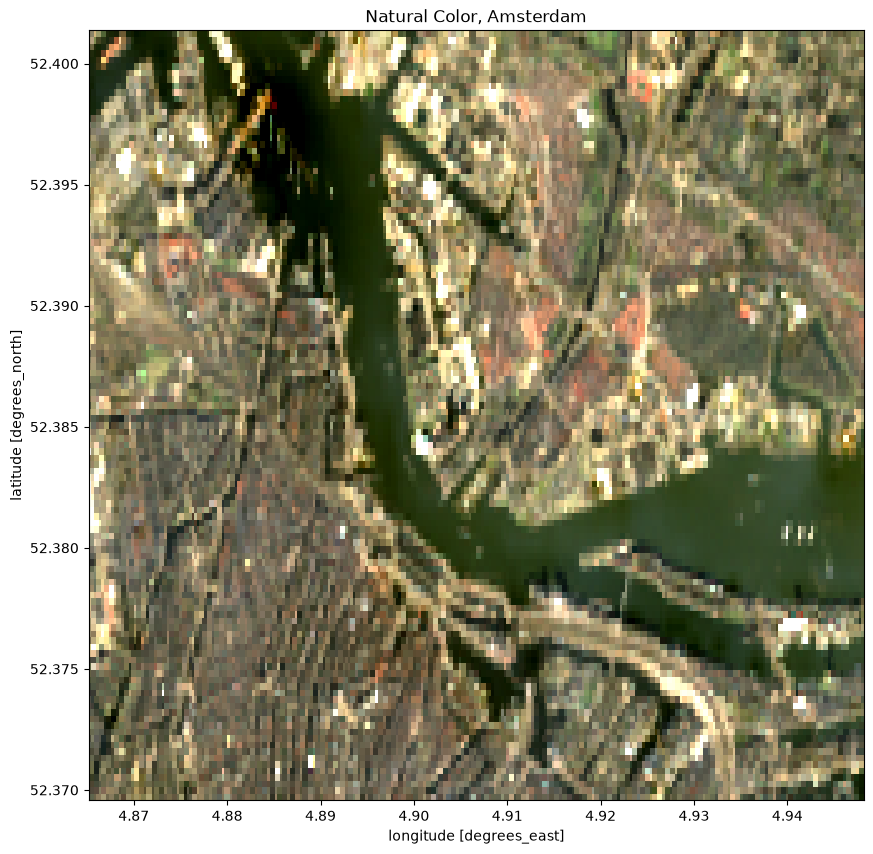

In [62]:
# This part is only for visualization purposes (to confirm the view of the interested area)
fig, ax = plt.subplots(figsize=(10, 10))

data_selected[["red", "green", "blue"]].to_array().plot.imshow(robust=True, ax=ax)
ax.set_title("Natural Color, Amsterdam");

In [ ]:
# Now proceed to load all available scenes within the specified time_of_interest
bands_of_interest = ["red", "green", "blue","lwir11", "emis", "drad", "urad", "atran", "swir16", "swir22", "coastal"]
data_all= odc.stac.stac_load(
    items, bands=bands_of_interest, bbox=bbox_of_interest,
        crs="EPSG:4326", # Latitude-Longitude
        resolution=scale, # Degrees
        chunks={"x": 500, "y": 500},
)#.isel(time=0)
data_all

<xarray.Dataset> Size: 11MB
Dimensions:      (latitude: 118, longitude: 308, time: 14)
Coordinates:
  * latitude     (latitude) float64 944B 52.4 52.4 52.4 ... 52.37 52.37 52.37
  * longitude    (longitude) float64 2kB 4.865 4.866 4.866 ... 4.947 4.948 4.948
  * time         (time) datetime64[ns] 112B 2025-02-03T10:33:55.901948 ... 20...
    spatial_ref  int32 4B 4326
Data variables:
    red          (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    green        (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    blue         (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    lwir11       (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    emis         (time, latitude, longitude) int16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    drad         (time, latitude, longitude) int16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    urad         (time, latitude, longitude) int16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    atran        (time, latitude, longitude) int16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    swir16       (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    swir22       (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>
    coastal      (time, latitude, longitude) uint16 1MB dask.array<chunksize=(1, 118, 308), meta=np.ndarray>

In [88]:
data_all.latitude.values

array([52.40123069, 52.40096119, 52.4006917 , 52.40042221, 52.40015271,
       52.39988322, 52.39961373, 52.39934423, 52.39907474, 52.39880525,
       52.39853575, 52.39826626, 52.39799677, 52.39772727, 52.39745778,
       52.39718829, 52.39691879, 52.3966493 , 52.39637981, 52.39611031,
       52.39584082, 52.39557133, 52.39530183, 52.39503234, 52.39476285,
       52.39449335, 52.39422386, 52.39395437, 52.39368487, 52.39341538,
       52.39314589, 52.39287639, 52.3926069 , 52.39233741, 52.39206791,
       52.39179842, 52.39152893, 52.39125943, 52.39098994, 52.39072045,
       52.39045095, 52.39018146, 52.38991197, 52.38964247, 52.38937298,
       52.38910349, 52.38883399, 52.3885645 , 52.38829501, 52.38802551,
       52.38775602, 52.38748653, 52.38721703, 52.38694754, 52.38667805,
       52.38640855, 52.38613906, 52.38586957, 52.38560007, 52.38533058,
       52.38506109, 52.38479159, 52.3845221 , 52.38425261, 52.38398311,
       52.38371362, 52.38344413, 52.38317463, 52.38290514, 52.38

In [ ]:
# Scale Factors for the lwir11, swir16, swir22, coastal bands, actually for all the surface reflectance bands
scale2 = 0.00341802 
offset2 = 149.0 
kelvin_celsius = 273.15 # convert from Kelvin to Celsius

for index in ["lwir11"]: # Thus, with the scale and offsets, lwir11 will equate to LST. To be more representative, this column can be renamed to LST.
    data_all[index] = data_all[index].astype(float) * scale2 + offset2 - kelvin_celsius

for index in ["swir16", "swir22", "coastal"]:
    data_all[index] = data_all[index].astype(float) * scale2 + offset2

In [90]:
# Scaling for remaining attributes
def scale_factor(index):
    if index == 'emis':
        scale = 0.0001
    elif index == 'drad':
        scale = 0.001
    elif index == 'urad':
        scale = 0.001
    elif index == 'atran':
        scale = 0.0001
    elif index == 'qa':
        scale = 0.01

    return scale

for index in ["emis", "drad", "urad", "atran"]:
    factor = scale_factor(index)
    data_all[index] = data_all[index].astype(float) * factor
    print(f"Conversion complete for {index} using scale factor {factor}")

Conversion complete for emis using scale factor 0.0001
Conversion complete for drad using scale factor 0.001
Conversion complete for urad using scale factor 0.001
Conversion complete for atran using scale factor 0.0001


In [91]:
median = data_all.median(dim="time").compute()

In [ ]:
# Goal: Load data into a GeoTIFF file
filename = "TEST_Landsat_median_2025-03-19_v2.tiff"

In [94]:
height = median.dims["latitude"]
width = median.dims["longitude"]

# Define the Coordinate Reference System (CRS) to be common Lat-Lon coordinates
# Define the tranformation using our bounding box so the Lat-Lon information is written to the GeoTIFF
gt = rasterio.transform.from_bounds(lower_left[1], lower_left[0], upper_right[1], upper_right[0], width, height)
median.rio.write_crs("epsg:4326", inplace=True)
median.rio.write_transform(transform=gt, inplace=True)

# Create the GeoTIFF output file using the defined parameters 
with rasterio.open(filename, 'w', driver='GTiff', width=width, height=height, 
                   crs='epsg:4326', transform=gt, count=8, compress='lzw', dtype='float64') as dst:
    dst.write(median.lwir11, 1)
    dst.write(median.emis, 2)
    dst.write(median.drad, 3) 
    dst.write(median.urad, 4)
    dst.write(median.atran, 5)
    dst.write(median.swir16, 6)
    dst.write(median.swir22, 7)
    dst.write(median.coastal, 8)
    dst.close()